# Six-Method Benchmark (n=30 positive controls)

Compares T21 RAG, GPT-5.4, Claude, Nemotron, MedRAG, and PaperQA2 against ground truth: loads saved answers from the fresh-round notebooks 3 (T21/GPT/Claude/Nemotron), 5 (MedRAG) and 6 (PaperQA2), all generated on the 1,594-article corpus (DS_INCLUDE_2026_09_02_DEEPINFRA_2048, 65,677 vectors), size-matches all six to the ground-truth length, scores BERTScore P/R/F + semantic similarity via `/embed_batch`, and saves summary CSVs and bar plots to `output/ScientificReportRevisionV1/six_method_benchmark/`.


## Cell 1 - Config

In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv

BASE_DIR = Path('..').resolve()
load_dotenv(BASE_DIR / '.env')

RESP_CSV    = BASE_DIR / 'output/ScientificReportRevisionV1/batch_eval/responses_latest.csv'
MEDRAG_CSV  = BASE_DIR / 'output/medrag_benchmark/medrag_benchmark_results.csv'
PAPERQA_CSV = BASE_DIR / 'output/paperqa_benchmark/paperqa_benchmark_results.csv'
OUTPUT_DIR  = BASE_DIR / 'output/ScientificReportRevisionV1/six_method_benchmark'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

T21_EMBED_BATCH_URL = os.getenv('T21_EMBED_BATCH_URL', 'http://localhost:8698/embed_batch')

# (key, label, Okabe-Ito colour) - first four match notebook 3's palette
MODELS = [
    ('t21',      'T21 RAG',  '#0072B2'),
    ('nemotron', 'Nemotron', '#D55E00'),
    ('gpt',      'GPT-5.4',  '#E69F00'),
    ('claude',   'Claude',   '#CC79A7'),
    ('medrag',   'MedRAG',   '#009E73'),
    ('paperqa',  'PaperQA2', '#56B4E9'),
]

print('Embed batch :', T21_EMBED_BATCH_URL)
print('Output dir  :', OUTPUT_DIR)

# ── Live collection gate (fresh-results round 2026-09-06) ─────────────────────
import requests as _rq_gate
EXPECTED_COLLECTION = 'DS_INCLUDE_2026_09_02_DEEPINFRA_2048'
EXPECTED_VECTORS, EXPECTED_DOCS = 65_677, 1_594
_hj = _rq_gate.get('http://localhost:8698/health', timeout=30).json()
_hc = _hj['config']['milvus_collection']
_hv = int(str(_hj['database']['total_vectors']).replace(',', ''))
_hd = int(str(_hj['database']['estimated_documents']).replace(',', ''))
assert (_hc, _hv, _hd) == (EXPECTED_COLLECTION, EXPECTED_VECTORS, EXPECTED_DOCS), (
    f'API serves {_hc} ({_hv:,}/{_hd:,}); expected {EXPECTED_COLLECTION} '
    f'({EXPECTED_VECTORS:,}/{EXPECTED_DOCS:,}) - the /embed_batch scorer must run '
    'against the same corpus the answers were generated on')
print(f'Collection gate OK: {_hc} ({_hv:,} vectors, {_hd:,} documents)')



Embed batch : http://localhost:8698/embed_batch
Output dir  : /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark
Collection gate OK: DS_INCLUDE_2026_09_02_DEEPINFRA_2048 (65,677 vectors, 1,594 documents)


## Cell 2 - Helpers (identical implementations to notebook 3 and the baseline notebooks 5/6)

In [4]:
import re as _re
import numpy as np
import pandas as pd
import requests as _req
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 18, 'axes.titlesize': 22, 'axes.titleweight': 'bold',
    'axes.labelsize': 20, 'xtick.labelsize': 18, 'ytick.labelsize': 18,
    'legend.fontsize': 17, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.linewidth': 2.4, 'xtick.major.width': 2.4, 'ytick.major.width': 2.4,
    'xtick.major.size': 7, 'ytick.major.size': 7,
    'axes.titlepad': 22,
    'pdf.fonttype': 42, 'figure.dpi': 110, 'savefig.dpi': 300,
})

_SENT_RE = _re.compile(r'(?<=[.!?])\s+')
_SEMI_RE = _re.compile(r'\s*;\s*')
_LIST_COMMA_RE = _re.compile(r',\s*(?:and\s+)?|\s+and\s+')
_PMC_TOK_RE = _re.compile(r'\s*\[{1,2}PMC\d{4,}[^\]]*\]{1,2}(?:\([^)]*\))?')
_ERR_MARKER_RE = _re.compile(r'\[[A-Z][A-Z0-9_]*_ERROR\]|too many concurrent', _re.I)

def _is_invalid_answer(text) -> bool:
    """Empty or API-error answers are EXCLUDED from scoring (NaN), never scored as 0.
    Genuine short model outputs ('I cannot answer.') are NOT invalid and stay in."""
    t = str(text or '').strip()
    return (not t) or t.lower() == 'nan' or bool(_ERR_MARKER_RE.search(t))

def _split_sents_sc(text):
    """Sentence/key-point splitter - identical to notebook 3 Cell 6 (comma-enumeration fallback)."""
    raw = _SENT_RE.split(str(text or '').strip())
    result = []
    for chunk in raw:
        chunk = chunk.strip()
        if not chunk:
            continue
        ends_terminal = bool(_re.search(r'[.!?]\s*$', chunk))
        if not ends_terminal and ';' in chunk:
            result.extend([p.strip() for p in _SEMI_RE.split(chunk) if p.strip()])
        elif not ends_terminal and chunk.count(',') >= 2:
            parts = [p.strip() for p in _LIST_COMMA_RE.split(chunk) if p.strip()]
            result.extend(parts if len(parts) > 1 else [chunk])
        else:
            result.append(chunk)
    return result

def _embed_batch_sc(texts):
    texts = [str(t) if t is not None else '' for t in texts]
    texts = ['no content' if not t.strip() else t for t in texts]
    r = _req.post(T21_EMBED_BATCH_URL, json={'texts': texts, 'mode': 'document'}, timeout=180)
    r.raise_for_status()
    return np.array(r.json()['embeddings'], dtype=np.float32)

def _bertscore_sc(reference, candidate):
    # NaN (excluded from means), not 0: empty/unsplittable input means 'cannot score'.
    _default = {'bertscore_p': float('nan'), 'bertscore_r': float('nan'),
                'bertscore_f': float('nan')}
    ref_sents, cand_sents = _split_sents_sc(reference), _split_sents_sc(candidate)
    if not ref_sents or not cand_sents:
        return _default
    try:
        vecs = _embed_batch_sc(ref_sents + cand_sents)
        vecs = vecs / np.maximum(np.linalg.norm(vecs, axis=1, keepdims=True), 1e-9)
        sim = vecs[:len(ref_sents)] @ vecs[len(ref_sents):].T
        recall, precision = float(sim.max(axis=1).mean()), float(sim.max(axis=0).mean())
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
        return {'bertscore_p': round(precision, 4), 'bertscore_r': round(recall, 4),
                'bertscore_f': round(f1, 4)}
    except Exception as exc:
        print(f'  [bertscore_err] {exc}')
        return {k: float('nan') for k in _default}

def _cos_sc(a, b):
    d = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / d) if d > 0 else 0.0

def _size_match(reference, candidate):
    """Trim candidate to the reference word count keeping its most GT-relevant sentences
    (identical to notebook 5 Cell 6b)."""
    ref, cand = str(reference or '').strip(), str(candidate or '').strip()
    if not ref or not cand:
        return cand
    target = len(ref.split())
    sents = _split_sents_sc(cand)
    if len(sents) <= 1 or len(cand.split()) <= target:
        return cand
    vecs = _embed_batch_sc([ref] + sents)
    vecs = vecs / np.maximum(np.linalg.norm(vecs, axis=1, keepdims=True), 1e-9)
    sims = vecs[1:] @ vecs[0]
    keep, used = set(), 0
    for idx in np.argsort(-sims):
        w = len(sents[idx].split())
        if used and used + w > target:
            continue
        keep.add(int(idx)); used += w
        if used >= target:
            break
    if not keep:
        keep = {int(np.argmax(sims))}
    return ' '.join(sents[i] for i in sorted(keep))

print('Helpers defined.')


Helpers defined.


## Cell 3 - Load and align the six arms

In [5]:
_norm = lambda s: _re.sub(r'\s+', ' ', str(s).strip().lower())

a = pd.read_csv(RESP_CSV)
m = pd.read_csv(MEDRAG_CSV)
# PaperQA2 is optional: if its results CSV is not on disk yet, run the FIVE-arm
# comparison now and re-run this notebook for the six-arm version once
# 6_paperqa2_baseline_benchmark.ipynb has written its results.
_has_pqa = PAPERQA_CSV.exists()
if not _has_pqa:
    print('[WARN] PaperQA2 results not found -> FIVE-arm comparison '
          '(re-run after notebook 6 finishes for the six-arm version).')
    MODELS = [t for t in MODELS if t[0] != 'paperqa']
p = pd.read_csv(PAPERQA_CSV) if _has_pqa else None
assert len(a) == len(m) == 30
assert (a['question'].map(_norm).values == m['question'].map(_norm).values).all()
assert (a['ground_truth'].map(_norm).values == m['ground_truth'].map(_norm).values).all()
if _has_pqa:
    assert len(p) == 30
    assert (a['question'].map(_norm).values == p['question'].map(_norm).values).all()

df = pd.DataFrame({
    'sl_no':        a['sl_no'],
    'question':     a['question'],
    'ground_truth': a['ground_truth'].fillna('').astype(str),
    't21_answer':      a['t21_answer'].fillna('').astype(str).apply(
        lambda x: _re.sub(r'\s{2,}', ' ', _PMC_TOK_RE.sub('', x)).strip()),
    'gpt_answer':      a['gpt_answer'].fillna('').astype(str),
    'claude_answer':   a['claude_answer'].fillna('').astype(str),
    'nemotron_answer': a['nemotron_answer'].fillna('').astype(str),
    'medrag_answer':   m['medrag_answer'].fillna('').astype(str),
})
if _has_pqa:
    df['paperqa_answer'] = (p['paperqa_clean'] if 'paperqa_clean' in p.columns
                            else p['paperqa_answer']).fillna('').astype(str)

print(f'{len(df)} aligned positive-control questions, 6 arms')
for k, lbl, _ in MODELS:
    wc = df[f'{k}_answer'].str.split().str.len().mean()
    print(f'  {lbl:9s} mean words: {wc:5.0f}')
print(f'  {"GT":9s} mean words: {df["ground_truth"].str.split().str.len().mean():5.0f}')


30 aligned positive-control questions, 6 arms
  T21 RAG   mean words:    95
  Nemotron  mean words:    98
  GPT-5.4   mean words:   125
  Claude    mean words:   134
  MedRAG    mean words:   280
  PaperQA2  mean words:   133
  GT        mean words:    76


## Cell 4 - Size-match to ground-truth length

In [6]:
for k, lbl, _ in MODELS:
    print(f'size-matching {lbl} ...')
    df[f'{k}_sm'] = [_size_match(r['ground_truth'], r[f'{k}_answer']) for _, r in df.iterrows()]

print()
gt_wc = df['ground_truth'].str.split().str.len().mean()
for k, lbl, _ in MODELS:
    full = df[f'{k}_answer'].str.split().str.len().mean()
    sm   = df[f'{k}_sm'].str.split().str.len().mean()
    print(f'  {lbl:9s} {full:5.0f} words -> size-matched {sm:5.0f} words')
print(f'  reference (GT) averages {gt_wc:.0f} words')


size-matching T21 RAG ...
size-matching Nemotron ...
size-matching GPT-5.4 ...
size-matching Claude ...
size-matching MedRAG ...
size-matching PaperQA2 ...

  T21 RAG      95 words -> size-matched    61 words
  Nemotron     98 words -> size-matched    78 words
  GPT-5.4     125 words -> size-matched    80 words
  Claude      134 words -> size-matched    81 words
  MedRAG      280 words -> size-matched    94 words
  PaperQA2    133 words -> size-matched    61 words
  reference (GT) averages 76 words


## Cell 5 - Score and save

In [7]:
from scipy.stats import wilcoxon

# BERTScore P/R/F on full and size-matched answers
for suffix, src_tpl in [('', '{k}_answer'), ('_sm', '{k}_sm')]:
    for k, lbl, _ in MODELS:
        print(f'scoring {lbl}{suffix or " (full)"} ...')
        res = [({'bertscore_p': float('nan'), 'bertscore_r': float('nan'),
                 'bertscore_f': float('nan')}
                if _is_invalid_answer(r[src_tpl.format(k=k)])
                else _bertscore_sc(r['ground_truth'], r[src_tpl.format(k=k)]))
               for _, r in df.iterrows()]
        for met in ('bertscore_p', 'bertscore_r', 'bertscore_f'):
            df[f'{k}{suffix}_{met}'] = [x[met] for x in res]

# Document-level semantic similarity (full and size-matched), one batched embed call each
n = len(df)
for suffix, src_tpl in [('', '{k}_answer'), ('_sm', '{k}_sm')]:
    texts = list(df['ground_truth']) + [t for k, _, _ in MODELS
                                        for t in df[src_tpl.format(k=k)]]
    vecs = _embed_batch_sc(texts)
    vecs = vecs / np.maximum(np.linalg.norm(vecs, axis=1, keepdims=True), 1e-9)
    gt_v = vecs[:n]
    for j, (k, _, _) in enumerate(MODELS):
        mv = vecs[(j + 1) * n:(j + 2) * n]
        _col = src_tpl.format(k=k)
        # Invalid answers were embedded only as the JSON-safe 'no content' placeholder -
        # their similarity is meaningless, so exclude them as NaN.
        df[f'{k}{suffix}_semantic_sim'] = [
            float('nan') if _is_invalid_answer(df[_col].iloc[i]) else _cos_sc(gt_v[i], mv[i])
            for i in range(n)
        ]

# Report excluded (empty/API-error) answers per model - these are NaN everywhere above
_excl = {lbl: int(df[f'{k}_answer'].map(_is_invalid_answer).sum()) for k, lbl, _ in MODELS}
if any(_excl.values()):
    print('[EXCLUDED] empty/API-error answers -> NaN, dropped from all means:',
          {k: v for k, v in _excl.items() if v})

# Summary table + Wilcoxon vs T21 (size-matched, Bonferroni x5)
METRICS = [('bertscore_p', 'Sentence-level adapted BERTScore P'), ('bertscore_r', 'Sentence-level adapted BERTScore R'),
           ('bertscore_f', 'Sentence-level adapted BERTScore F1'), ('semantic_sim', 'Semantic Similarity')]
rows = []
for met, met_lbl in METRICS:
    for suffix in ('', '_sm'):
        row = {'metric': met_lbl + (' (size-matched)' if suffix else ' (full)')}
        for k, lbl, _ in MODELS:
            row[lbl] = round(df[f'{k}{suffix}_{met}'].mean(), 4)
        rows.append(row)
summary = pd.DataFrame(rows)
print(); print(summary.to_string(index=False))

print('\nWilcoxon vs T21 (size-matched, Bonferroni x5):')
for met, met_lbl in [('bertscore_f', 'Sentence-level adapted BERTScore F1'), ('semantic_sim', 'Semantic Similarity')]:
    for k, lbl, _ in MODELS[1:]:
        try:
            _a, _b = df[f't21_sm_{met}'], df[f'{k}_sm_{met}']
            _m = _a.notna() & _b.notna()   # pairwise-drop excluded rows
            pv = min(wilcoxon(_a[_m], _b[_m]).pvalue * 5, 1.0)
            print(f'  {met_lbl:13s} T21 vs {lbl:9s}: p={pv:.3f}{"  *" if pv < 0.05 else ""}')
        except Exception as e:
            print(f'  {met_lbl:13s} T21 vs {lbl:9s}: n/a ({e})')

df.to_csv(OUTPUT_DIR / 'six_method_scored.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'six_method_summary.csv', index=False)
print(f'\nSaved -> {OUTPUT_DIR / "six_method_scored.csv"}')
print(f'Saved -> {OUTPUT_DIR / "six_method_summary.csv"}')


scoring T21 RAG (full) ...
scoring Nemotron (full) ...
scoring GPT-5.4 (full) ...
scoring Claude (full) ...
scoring MedRAG (full) ...
scoring PaperQA2 (full) ...
scoring T21 RAG_sm ...
scoring Nemotron_sm ...
scoring GPT-5.4_sm ...
scoring Claude_sm ...
scoring MedRAG_sm ...
scoring PaperQA2_sm ...

                                            metric  T21 RAG  Nemotron  GPT-5.4  Claude  MedRAG  PaperQA2
         Sentence-level adapted BERTScore P (full)   0.5471    0.5498   0.5669  0.5732  0.5381    0.5060
 Sentence-level adapted BERTScore P (size-matched)   0.6081    0.5819   0.6264  0.6293  0.6035    0.5964
         Sentence-level adapted BERTScore R (full)   0.5741    0.5274   0.5544  0.5468  0.5846    0.5604
 Sentence-level adapted BERTScore R (size-matched)   0.5600    0.5216   0.5404  0.5316  0.5598    0.5403
        Sentence-level adapted BERTScore F1 (full)   0.5578    0.5332   0.5565  0.5557  0.5545    0.5254
Sentence-level adapted BERTScore F1 (size-matched)   0.5789    0.5443

## Cell 6 - Bar plots

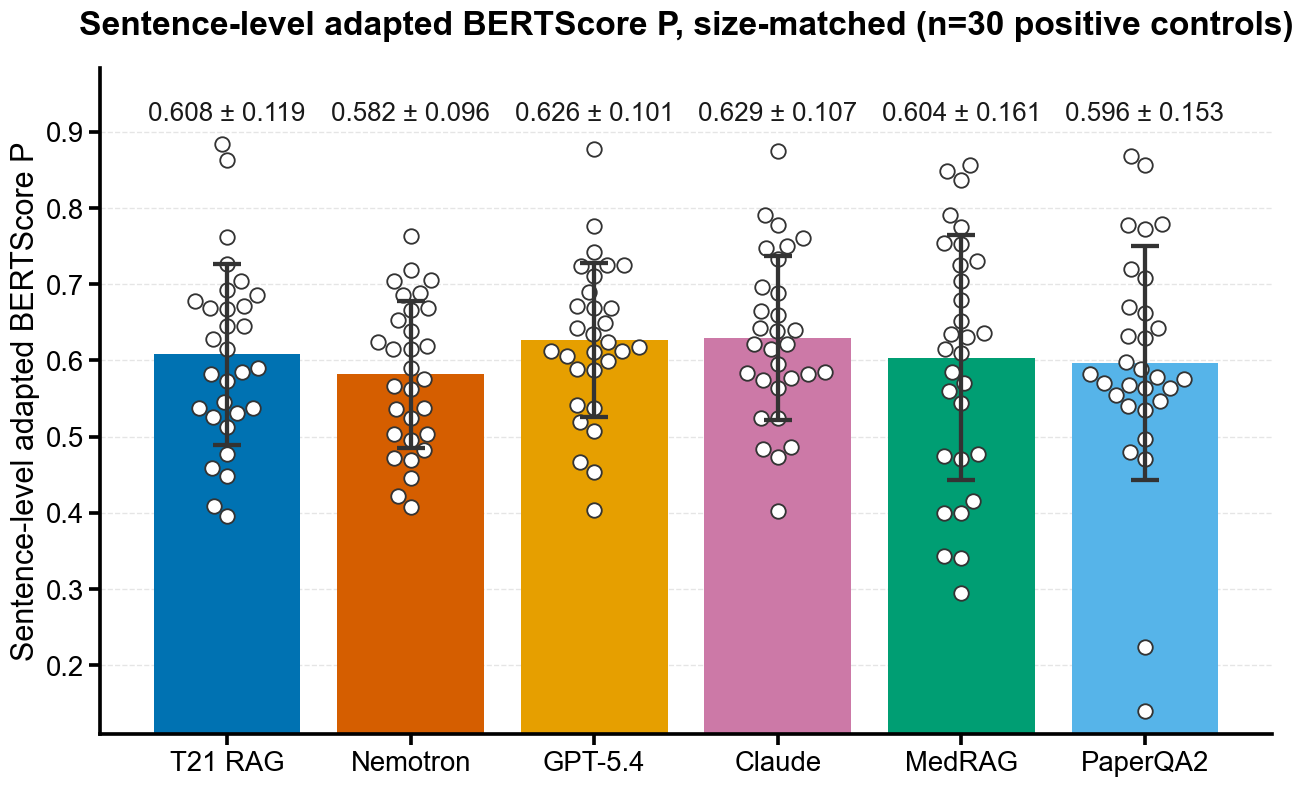

Saved -> six_method_bertscore_p_summary.jpg/.pdf


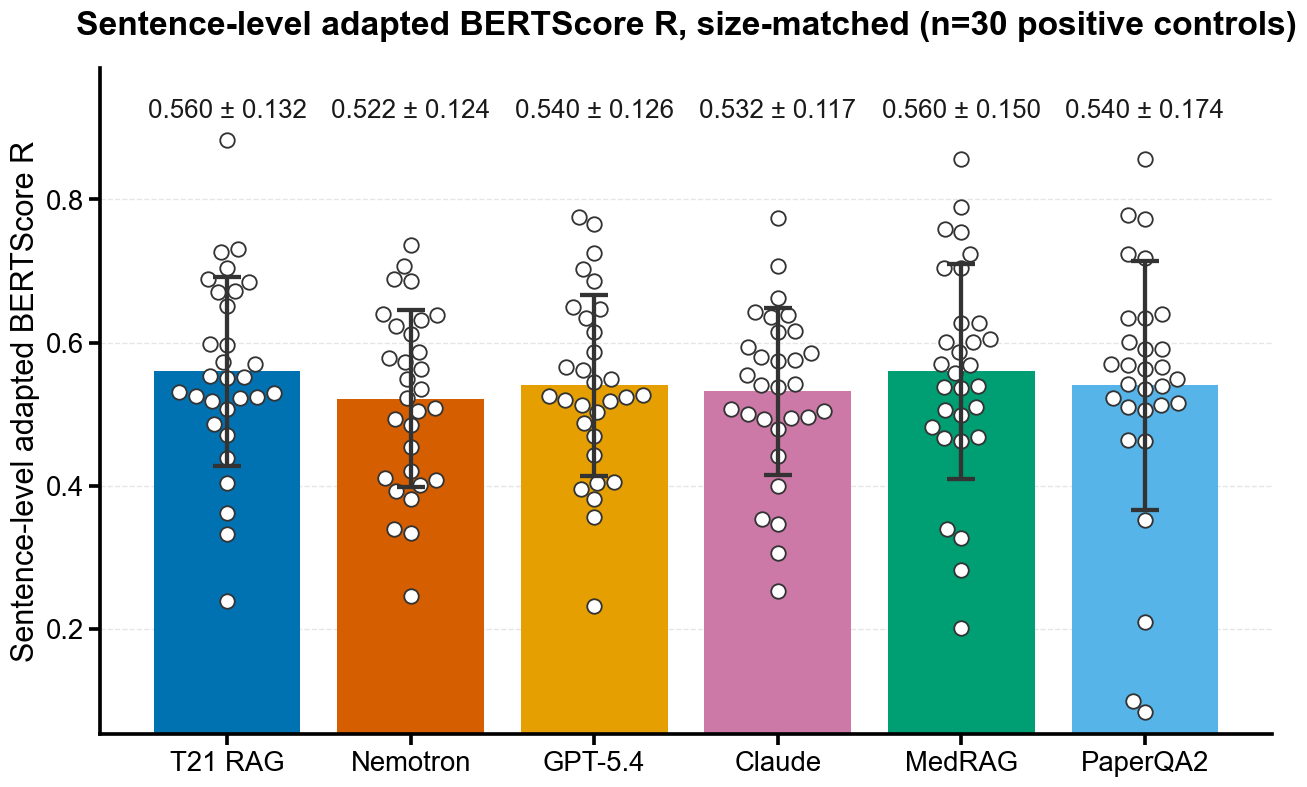

Saved -> six_method_bertscore_r_summary.jpg/.pdf


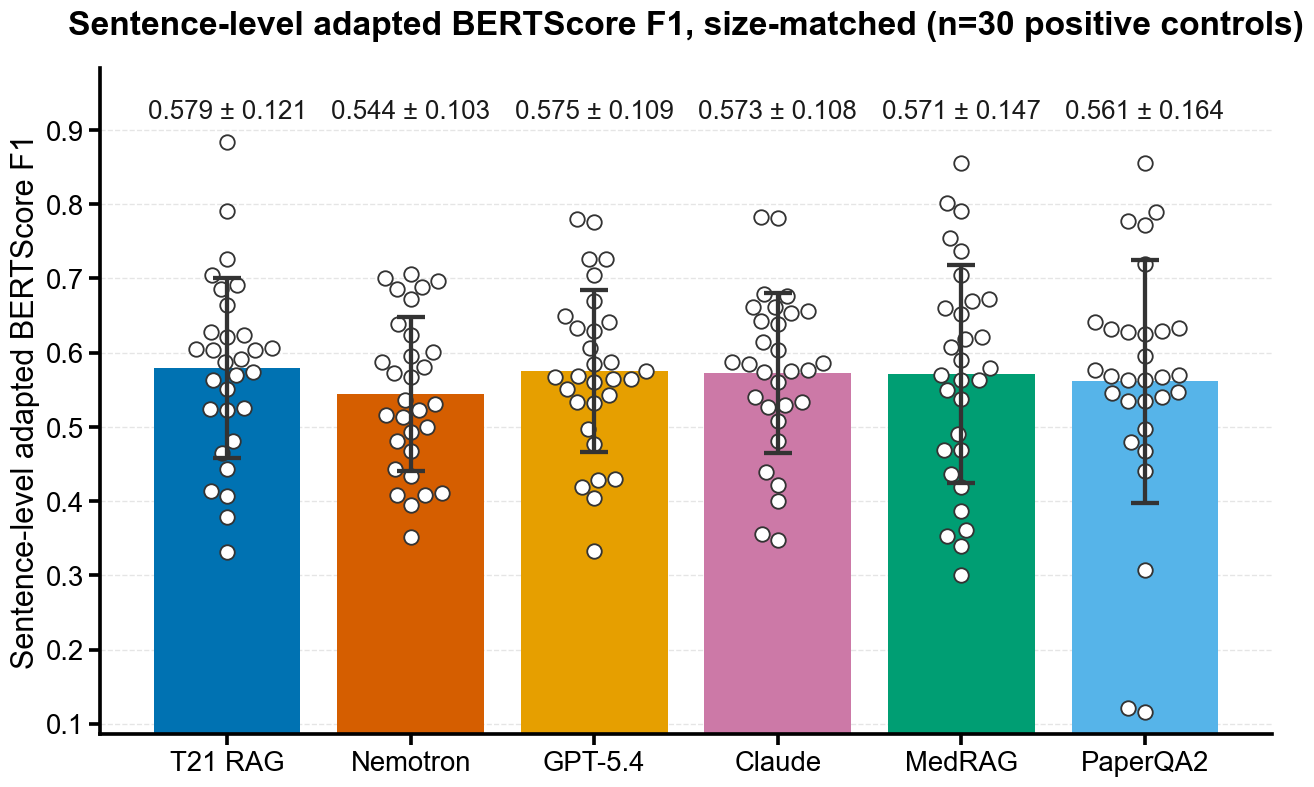

Saved -> six_method_bertscore_f_summary.jpg/.pdf


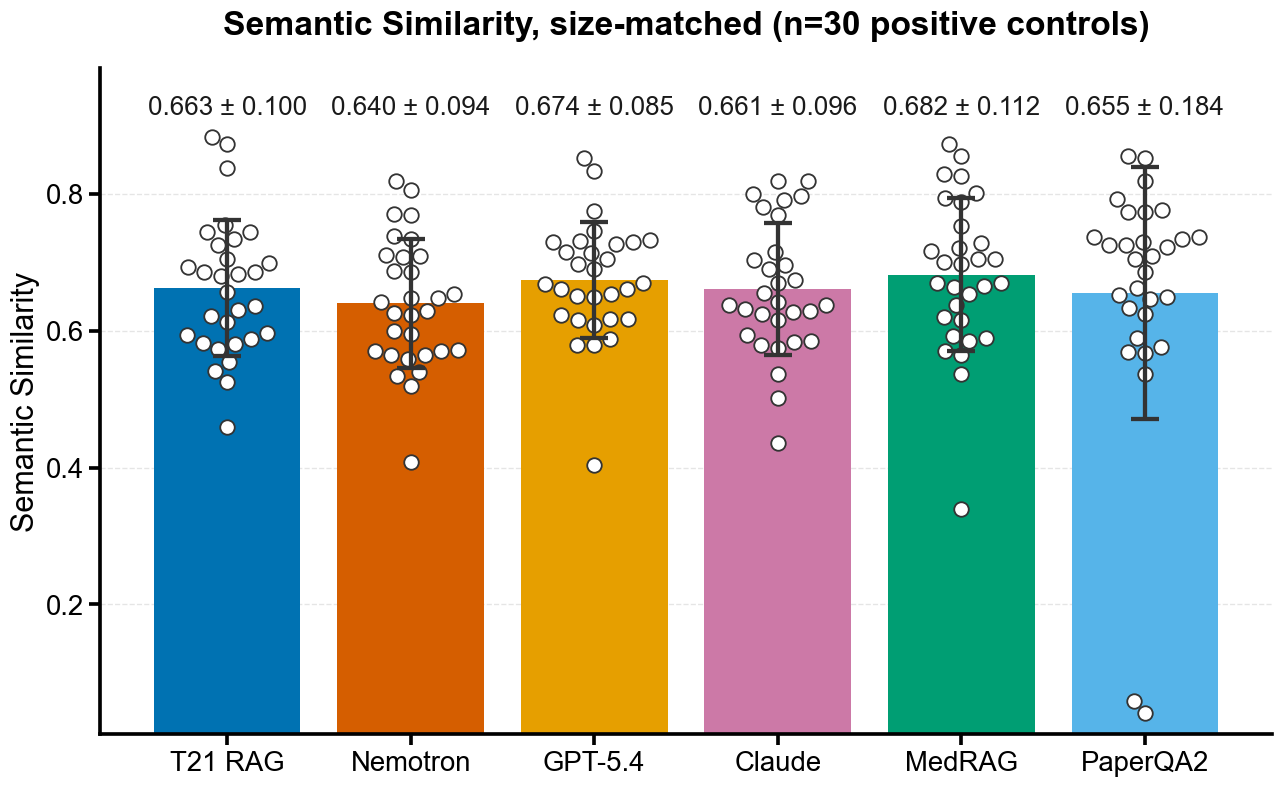

Saved -> six_method_semantic_sim_summary.jpg/.pdf


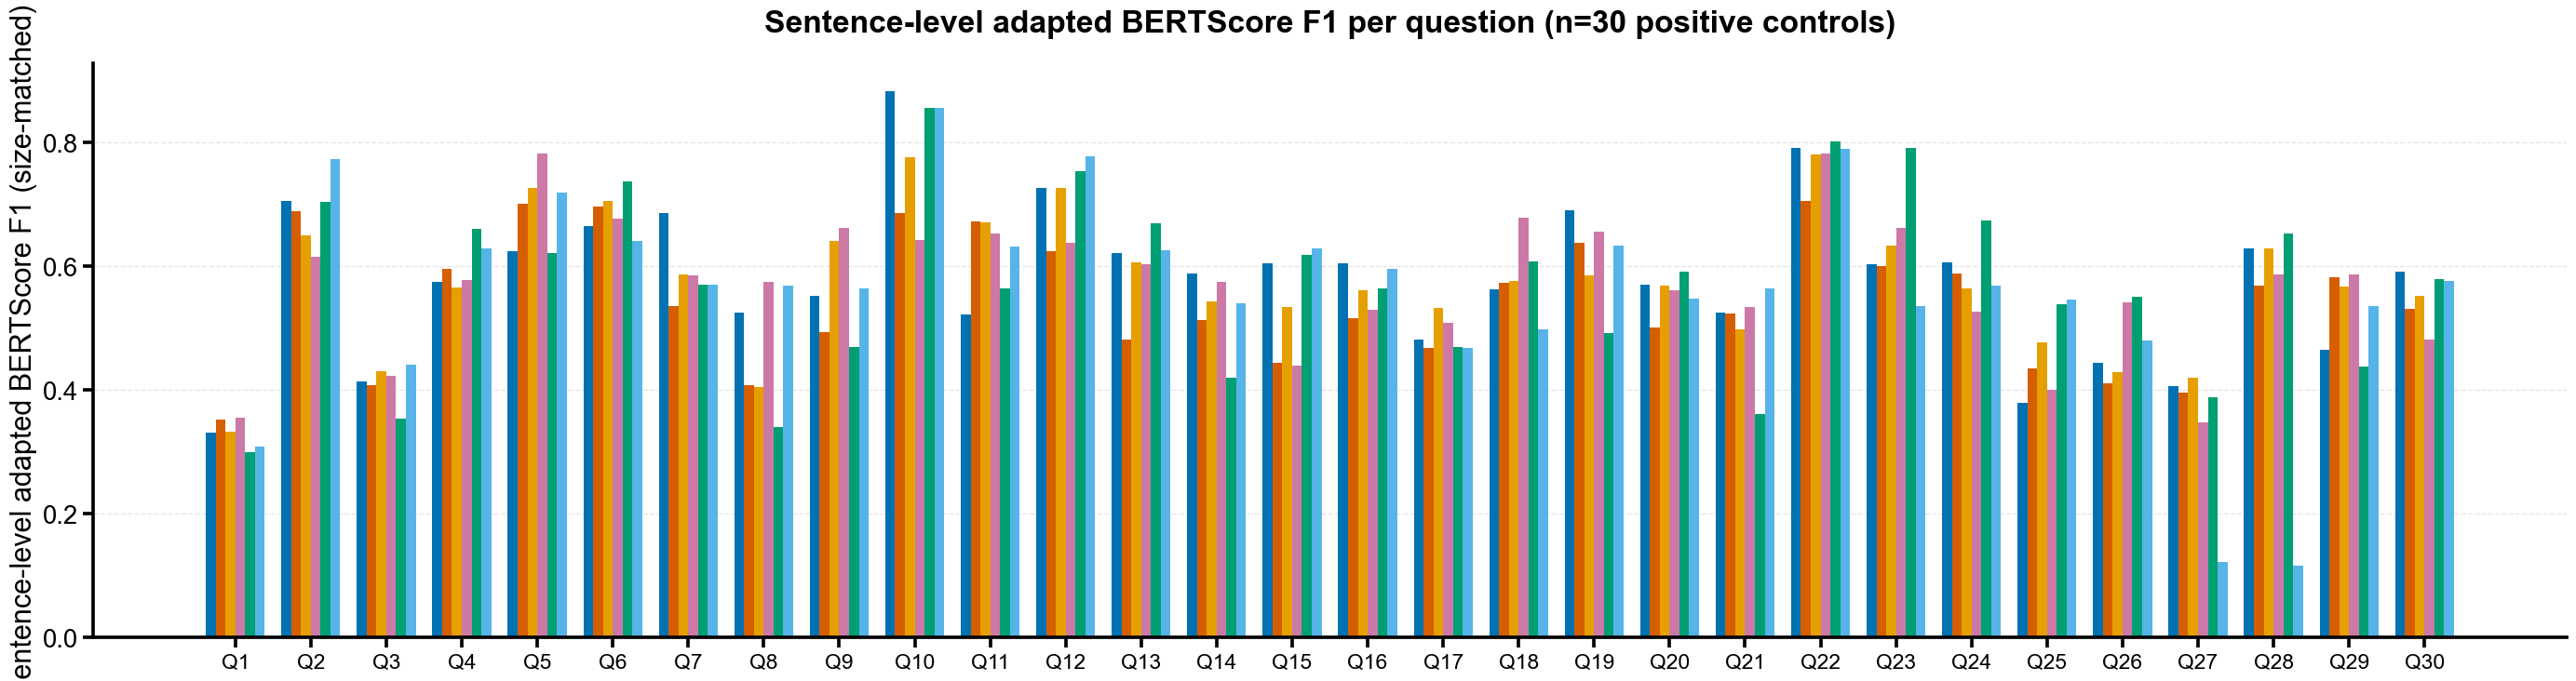

Saved -> six_method_bertscore_f_per_question.jpg/.pdf
Saved -> six_method_models_legend.jpg/.pdf


In [8]:
def _swarm_offsets(vals, y_bin=0.022, x_step=0.07, gap=0.11, max_half=0.34):
    """Deterministic beeswarm offsets fanning out on BOTH sides of a central
    gap (+gap, -gap, +gap+step, -gap-step, ...) so the error bar drawn down
    the middle of the bar stays clear of every dot."""
    vals = np.asarray(vals, dtype=float)
    offs = np.zeros(len(vals))
    bins = {}
    for idx in np.argsort(vals):
        b = int(round(vals[idx] / y_bin))
        n = bins.get(b, 0)
        m = n // 2
        sign = 1 if n % 2 == 0 else -1
        offs[idx] = sign * min(gap + m * x_step, max_half)
        bins[b] = n + 1
    return offs

labels  = [lbl for _, lbl, _ in MODELS]
colors  = [c for _, _, c in MODELS]

# Summary bars (mean +/- SEM) - one figure per metric, size-matched scores
for met, met_lbl in METRICS:
    means = [df[f'{k}_sm_{met}'].mean() for k, _, _ in MODELS]
    stds  = [df[f'{k}_sm_{met}'].std()  for k, _, _ in MODELS]
    fig, ax = plt.subplots(figsize=(12, 7.5))
    bars = ax.bar(labels, means, color=colors)
    long = pd.concat([pd.DataFrame({'method': lbl, 'val': df[f'{k}_sm_{met}'].dropna()})
                      for k, lbl, _ in MODELS], ignore_index=True)
    sns.swarmplot(x='method', y='val', data=long, order=labels, ax=ax,
                  size=9.5, color='white', edgecolor='#333333', linewidth=1.2, zorder=3)
    ax.set_xlabel('')
    col_max = [float(df[f'{k}_sm_{met}'].max()) for k, _, _ in MODELS]
    y_dot_max = max(col_max)
    y_dot_min = min(float(df[f'{k}_sm_{met}'].min()) for k, _, _ in MODELS)
    for j, (m_, s_) in enumerate(zip(means, stds)):
        ax.errorbar(j, m_, yerr=s_, fmt='none', ecolor='#333333',
                    elinewidth=2.8, capsize=9, capthick=2.8, zorder=4)
    y_lab = max(max(v + s, cmx) for v, s, cmx in zip(means, stds, col_max)) + 0.025
    for b, v, s, cmx in zip(bars, means, stds, col_max):
        ax.text(b.get_x() + b.get_width() / 2, y_lab, f'{v:.3f} \u00b1 {s:.3f}',
                ha='center', va='bottom', fontsize=17, color='#1a1a1a', zorder=5)
    ax.set_ylabel(met_lbl)
    ax.set_title(f'{met_lbl}, size-matched (n=30 positive controls)')
    y_bottom = min(0.2, y_dot_min - 0.03)   # start at 0.2 unless a data point sits lower
    y_top = max(max(max(m + s, cx) for m, s, cx in zip(means, stds, col_max)) + 0.10, y_dot_max * 1.06)
    ax.set_ylim(y_bottom, y_top)
    ax.grid(axis='y', color='#E5E5E5', linewidth=0.9, linestyle='--')
    ax.set_axisbelow(True)
    fig.tight_layout()
    for ext in ('jpg', 'pdf'):
        fig.savefig(OUTPUT_DIR / f'six_method_{met}_summary.{ext}', bbox_inches='tight')
    plt.show()
    print(f'Saved -> six_method_{met}_summary.jpg/.pdf')

# Per-question grouped bars - BERTScore F, size-matched
n_q = len(df)
x = np.arange(n_q)
w = 0.13
fig, ax = plt.subplots(figsize=(min(max(20, n_q * 0.85), 26), 7))
for j, (k, lbl, c) in enumerate(MODELS):
    ax.bar(x + (j - 2.5) * w, df[f'{k}_sm_bertscore_f'], width=w, label=lbl, color=c)
ax.set_xticks(x)
ax.set_xticklabels([f'Q{s}' for s in df['sl_no']], rotation=0, fontsize=15)
ax.set_ylabel('Sentence-level adapted BERTScore F1 (size-matched)')
ax.set_title('Sentence-level adapted BERTScore F1 per question (n=30 positive controls)')
ax.grid(axis='y', color='#E5E5E5', linewidth=0.9, linestyle='--')
ax.set_axisbelow(True)
fig.tight_layout()
for ext in ('jpg', 'pdf'):
    fig.savefig(OUTPUT_DIR / f'six_method_bertscore_f_per_question.{ext}', bbox_inches='tight')
plt.show()
print('Saved -> six_method_bertscore_f_per_question.jpg/.pdf')

# model legend saved as a separate image (shared by the per-question chart and heatmaps)
import matplotlib.patches as mpatches
_handles = [mpatches.Patch(facecolor=c, edgecolor='#333333', linewidth=1.0, label=lbl)
            for _, lbl, c in MODELS]
fig_lg = plt.figure(figsize=(16, 1.3))
lg = fig_lg.legend(handles=_handles, loc='center', ncol=6, frameon=False,
                   fontsize=24, handlelength=1.8, handleheight=1.4, columnspacing=1.8)
for ext in ('jpg', 'pdf'):
    fig_lg.savefig(OUTPUT_DIR / f'six_method_models_legend.{ext}', bbox_inches='tight')
plt.close(fig_lg)
print('Saved -> six_method_models_legend.jpg/.pdf')


## Cell 7 - Per-question z-score heatmap (models x questions)

One heatmap per metric (size-matched scores). Each ROW (question) is z-score
normalized across the six models: z = (score - question mean) / question SD. Purple cells mean the model outperformed the other models on that question,
orange cells mean it underperformed, and white marks the question average
(diverging colour-blind-safe PuOr scale, robust in grayscale print). Cells are square and unannotated; exact values are in six_method_scored.csv. This view answers "which
model wins on which question" independently of how hard each question is.

A question where the MedRAG answer is missing (Q12) contributes NaN for that arm
only (gray cell); rows with zero variance across models are left at 0.

Output: `six_method_<metric>_zscore_heatmap.{pdf,jpg}` per metric, vector PDF.


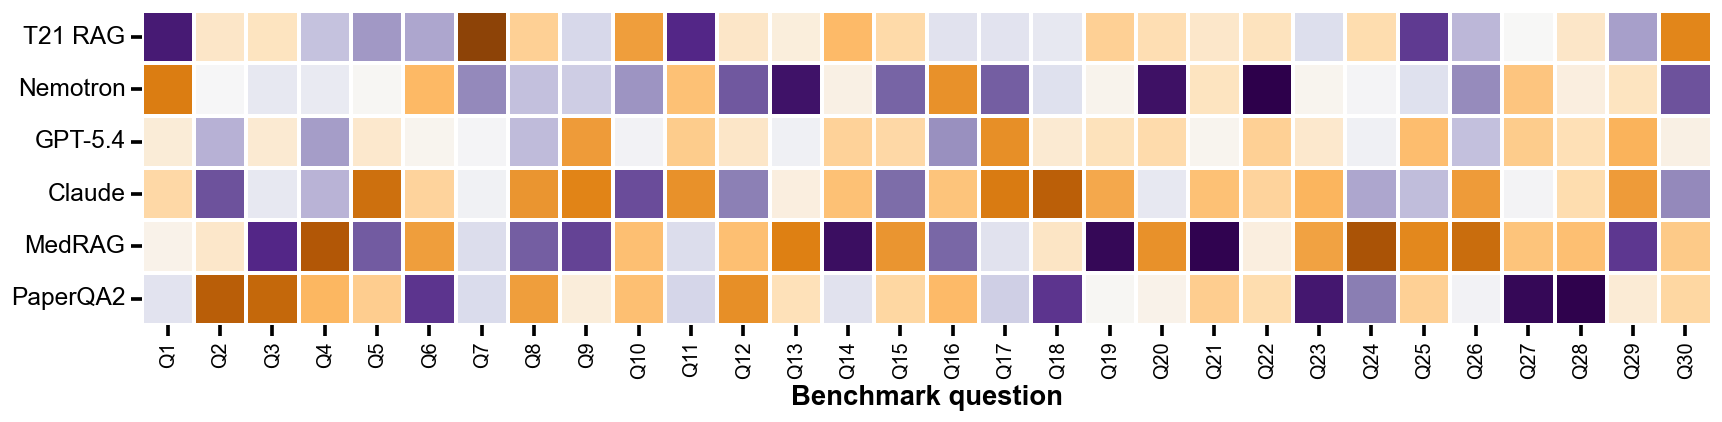

Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_bertscore_p_zscore_heatmap.{pdf,jpg} + six_method_bertscore_p_zscore_colorbar.{pdf,jpg}


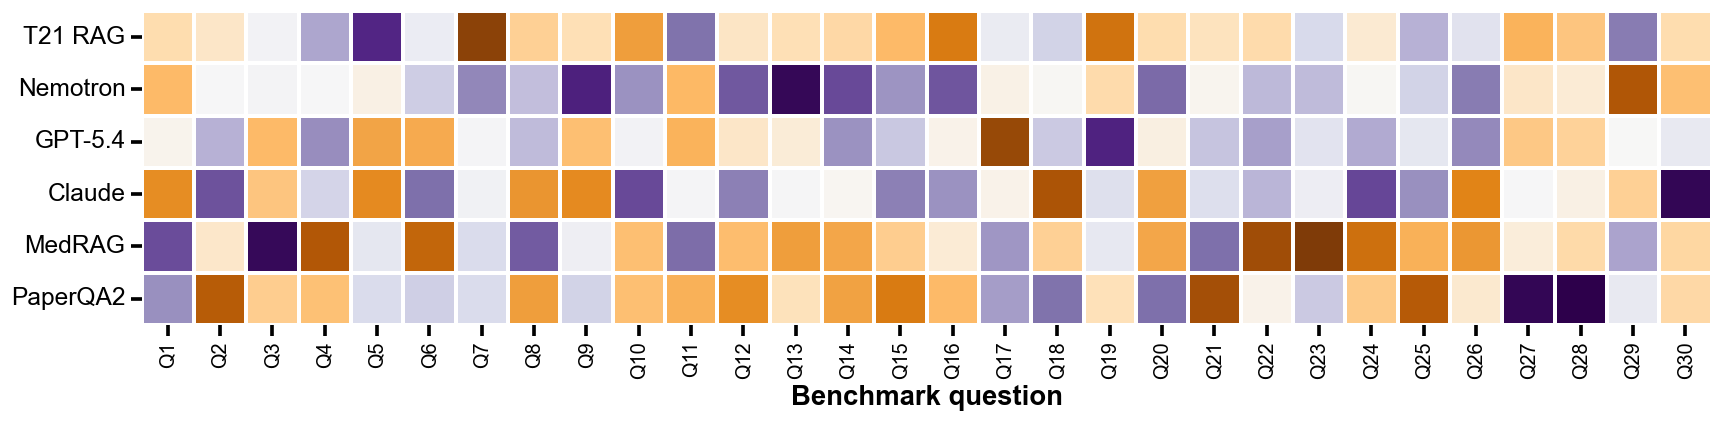

Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_bertscore_r_zscore_heatmap.{pdf,jpg} + six_method_bertscore_r_zscore_colorbar.{pdf,jpg}


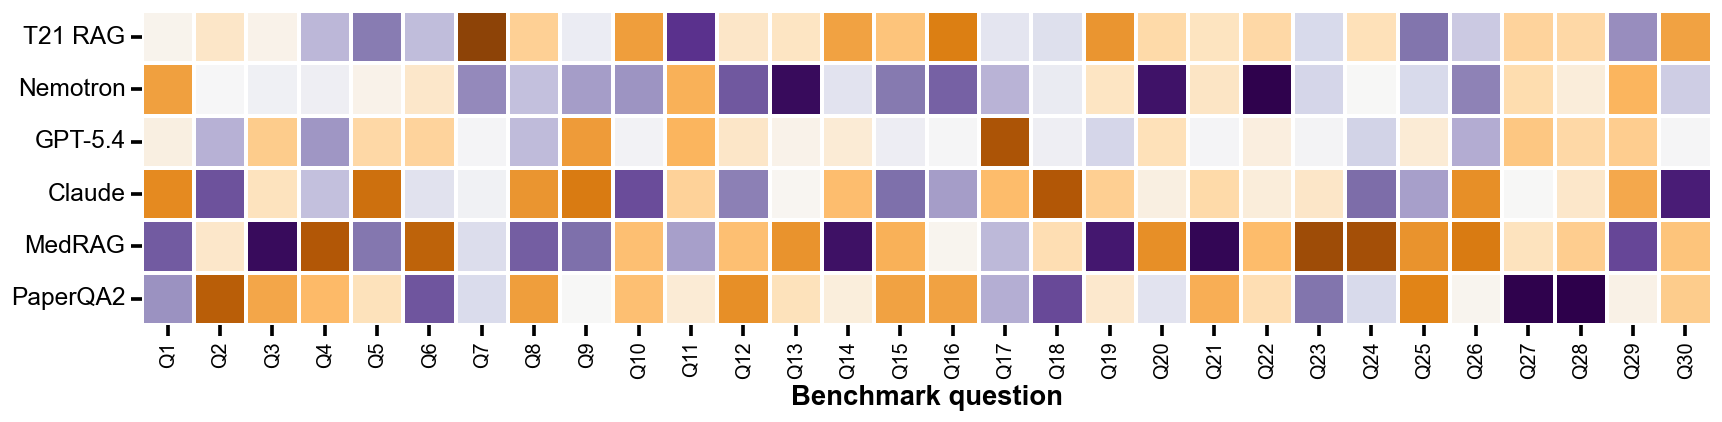

Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_bertscore_f_zscore_heatmap.{pdf,jpg} + six_method_bertscore_f_zscore_colorbar.{pdf,jpg}


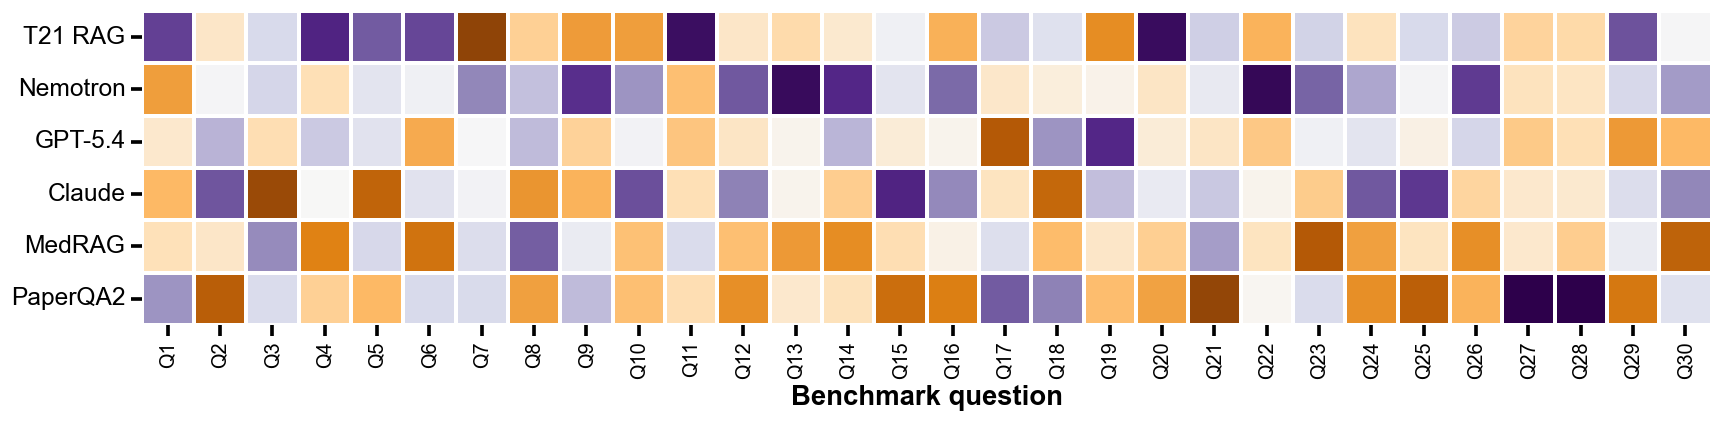

Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_semantic_sim_zscore_heatmap.{pdf,jpg} + six_method_semantic_sim_zscore_colorbar.{pdf,jpg}


In [9]:
# ---- Cell 7: per-question z-score heatmap (models x questions) ----
import matplotlib as mpl
q_labels = [f'Q{s}' for s in df['sl_no']]

for met, met_lbl in METRICS:
    mat = np.column_stack([df[f'{k}_sm_{met}'].to_numpy(dtype=float) for k, _, _ in MODELS])
    mu = np.nanmean(mat, axis=1, keepdims=True)   # per-question mean across models
    sd = np.nanstd(mat, axis=1, keepdims=True)    # per-question SD across models
    z = np.where(sd > 0, (mat - mu) / np.where(sd == 0, 1, sd), 0.0)

    zdf = pd.DataFrame(z, index=q_labels, columns=[lbl for _, lbl, _ in MODELS]).T
    vmax = np.nanmax(np.abs(z)) if np.isfinite(np.nanmax(np.abs(z))) else 2.0

    fig, ax = plt.subplots(figsize=(16, 4.5))
    ax.set_facecolor('0.85')   # NaN cells (missing answers) render gray
    # diverging colour-blind-safe PuOr scale (grayscale-robust): purple (below
    # the question average) -> white (average) -> orange (above it)
    sns.heatmap(zdf, ax=ax, cmap='PuOr_r', center=0, vmin=-vmax, vmax=vmax,
                annot=False, square=True,
                linewidths=1.5, linecolor='white',
                cbar=False)
    ax.set_xlabel('Benchmark question', fontsize=18, fontweight='bold')
    ax.set_ylabel('')
    ax.tick_params(axis='x', labelsize=13, rotation=90)
    ax.tick_params(axis='y', labelsize=16, rotation=0)
    plt.setp(ax.get_xticklabels(), ha='center')
    fig.tight_layout()
    for ext in ('jpg', 'pdf'):
        fig.savefig(OUTPUT_DIR / f'six_method_{met}_zscore_heatmap.{ext}', bbox_inches='tight')
    plt.show()

    # standalone horizontal colorbar image for this metric's heatmap
    fig_cb, ax_cb = plt.subplots(figsize=(7.0, 1.1))
    cb = mpl.colorbar.ColorbarBase(ax_cb, cmap=plt.get_cmap('PuOr_r'),
                                   norm=mpl.colors.Normalize(vmin=-vmax, vmax=vmax),
                                   orientation='horizontal')
    cb.ax.tick_params(labelsize=14, width=1.8, length=5.0)
    cb.set_label('z-score (within question, across models)', fontsize=16)
    cb.outline.set_linewidth(1.8)
    fig_cb.subplots_adjust(bottom=0.55, top=0.95, left=0.03, right=0.97)
    for ext in ('jpg', 'pdf'):
        fig_cb.savefig(OUTPUT_DIR / f'six_method_{met}_zscore_colorbar.{ext}', bbox_inches='tight')
    plt.close(fig_cb)
    print(f'Saved -> {OUTPUT_DIR}/six_method_{met}_zscore_heatmap.{{pdf,jpg}} + six_method_{met}_zscore_colorbar.{{pdf,jpg}}')


## Cell 8 - Starred z-score heatmap with per-model win counts

Same per-question z-score heatmap as Cell 7, with two additions:

- A `*` marks, for each question (column), the model with the highest z-score,
  i.e. the best-scoring model on that question. Ties within 1e-12 share the star;
  an arm with a missing answer (NaN, gray cell) can never win.
- A final gray column, `Total *`, gives each model's win count: how many of the
  30 questions that model starred for this metric.

One figure per metric (size-matched scores), same PuOr scale and colorbar as
Cell 7. Win counts for all metrics are also saved to
`six_method_zscore_win_counts.csv`.

Output: `six_method_<metric>_zscore_heatmap_starred.{pdf,jpg}` per metric.

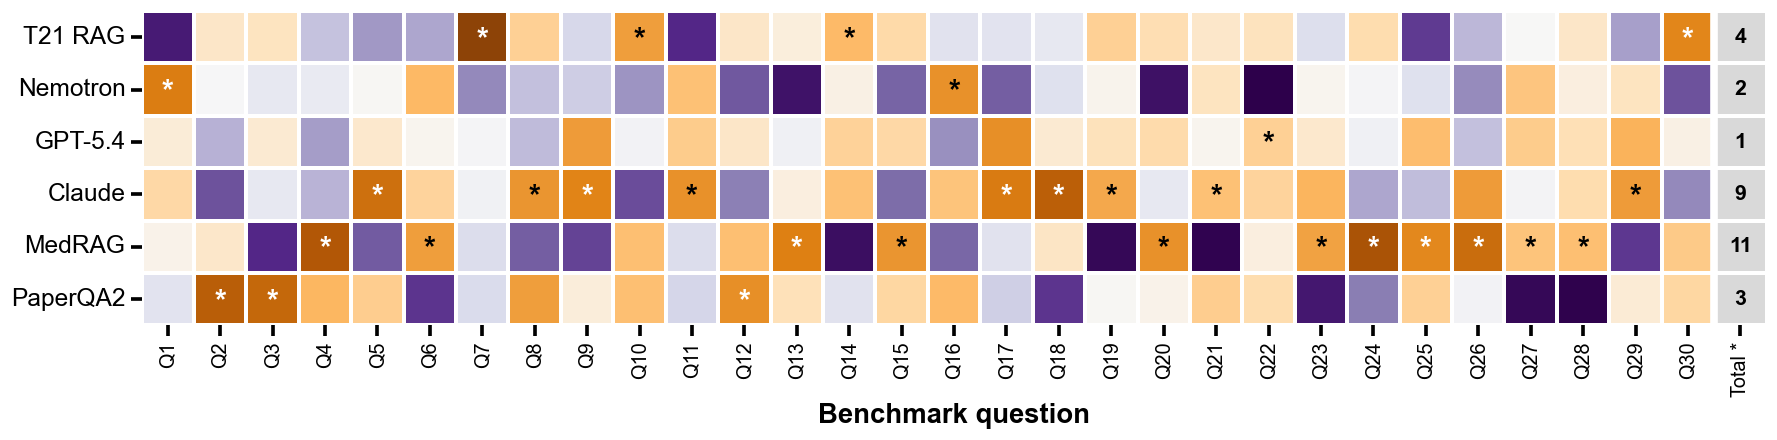

Sentence-level adapted BERTScore P: wins per model -> T21 RAG=4, Nemotron=2, GPT-5.4=1, Claude=9, MedRAG=11, PaperQA2=3
Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_bertscore_p_zscore_heatmap_starred.{pdf,jpg}


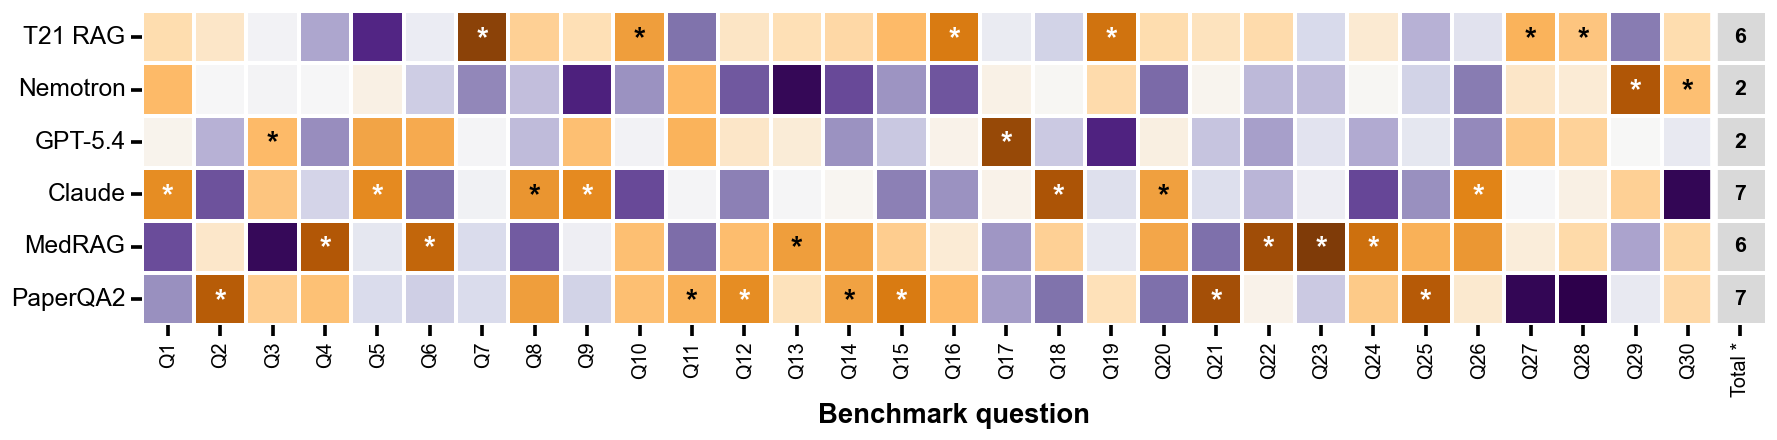

Sentence-level adapted BERTScore R: wins per model -> T21 RAG=6, Nemotron=2, GPT-5.4=2, Claude=7, MedRAG=6, PaperQA2=7
Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_bertscore_r_zscore_heatmap_starred.{pdf,jpg}


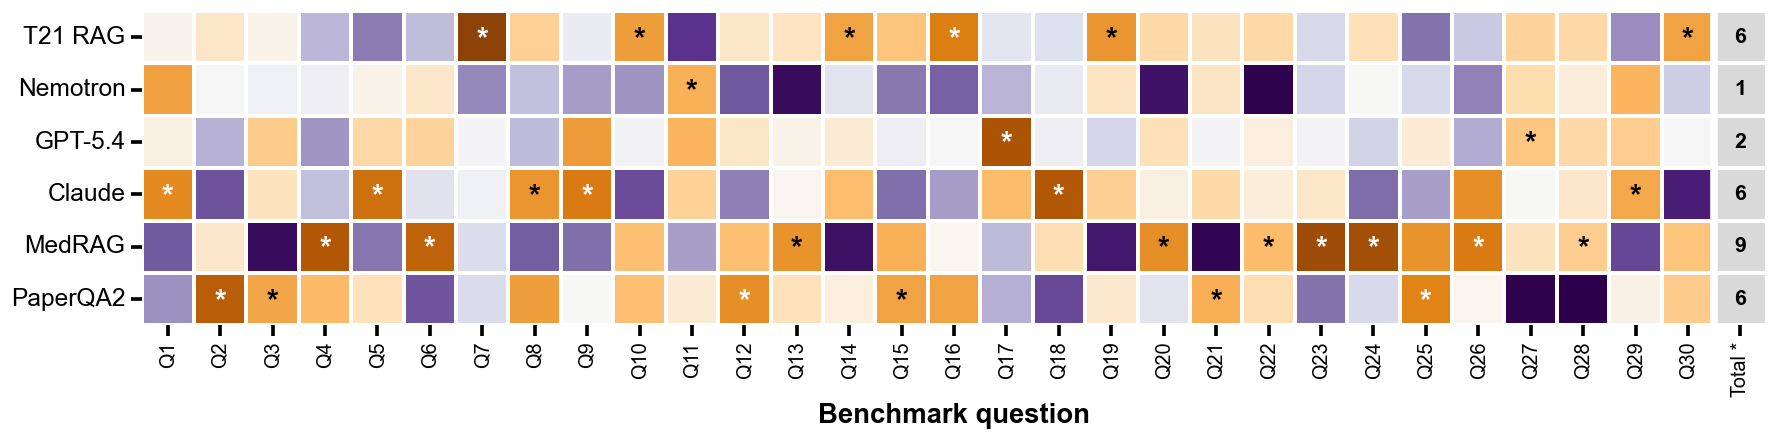

Sentence-level adapted BERTScore F1: wins per model -> T21 RAG=6, Nemotron=1, GPT-5.4=2, Claude=6, MedRAG=9, PaperQA2=6
Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_bertscore_f_zscore_heatmap_starred.{pdf,jpg}


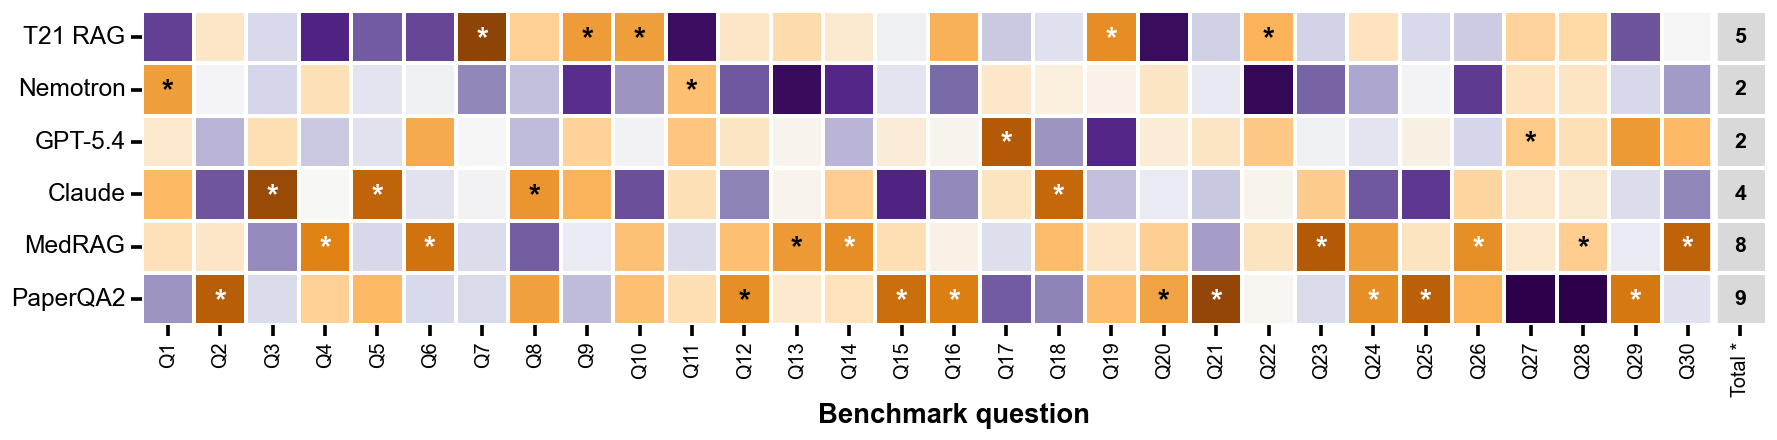

Semantic Similarity: wins per model -> T21 RAG=5, Nemotron=2, GPT-5.4=2, Claude=4, MedRAG=8, PaperQA2=9
Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_semantic_sim_zscore_heatmap_starred.{pdf,jpg}

                             metric  T21 RAG  Nemotron  GPT-5.4  Claude  MedRAG  PaperQA2
 Sentence-level adapted BERTScore P        4         2        1       9      11         3
 Sentence-level adapted BERTScore R        6         2        2       7       6         7
Sentence-level adapted BERTScore F1        6         1        2       6       9         6
                Semantic Similarity        5         2        2       4       8         9
Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/six_method_benchmark/six_method_zscore_win_counts.csv


In [10]:
# ---- Cell 8: starred z-score heatmap + per-model win-count column ----
import matplotlib as mpl
q_labels = [f'Q{s}' for s in df['sl_no']]
model_lbls = [lbl for _, lbl, _ in MODELS]
n_q, n_m = len(q_labels), len(MODELS)

win_rows = []
for met, met_lbl in METRICS:
    mat = np.column_stack([df[f'{k}_sm_{met}'].to_numpy(dtype=float) for k, _, _ in MODELS])
    mu = np.nanmean(mat, axis=1, keepdims=True)   # per-question mean across models
    sd = np.nanstd(mat, axis=1, keepdims=True)    # per-question SD across models
    z = np.where(sd > 0, (mat - mu) / np.where(sd == 0, 1, sd), 0.0)

    # star = highest z per question (ties share the star; NaN arms can never win)
    star = np.zeros_like(z, dtype=bool)
    for i in range(n_q):
        row = np.where(np.isnan(mat[i]), -np.inf, z[i])
        best = row.max()
        if np.isfinite(best):
            star[i] = row >= best - 1e-12
    wins = star.sum(axis=0).astype(int)           # stars per model across all questions
    win_rows.append({'metric': met_lbl, **dict(zip(model_lbls, wins))})

    # models x questions + one extra NaN column (renders gray) holding the win counts
    z_ext = np.column_stack([z.T, np.full(n_m, np.nan)])
    zdf = pd.DataFrame(z_ext, index=model_lbls, columns=q_labels + ['Total *'])
    vmax = np.nanmax(np.abs(z)) if np.isfinite(np.nanmax(np.abs(z))) else 2.0

    fig, ax = plt.subplots(figsize=(16.5, 4.5))
    ax.set_facecolor('0.85')   # NaN cells (missing answers + count column) render gray
    sns.heatmap(zdf, ax=ax, cmap='PuOr_r', center=0, vmin=-vmax, vmax=vmax,
                annot=False, square=True,
                linewidths=1.5, linecolor='white',
                cbar=False)
    # star the best model per question (white star on the dark high-z cells)
    for i in range(n_q):
        for j in range(n_m):
            if star[i, j]:
                c = 'white' if z[i, j] > 0.55 * vmax else 'black'
                ax.text(i + 0.5, j + 0.5, '*', ha='center', va='center_baseline',
                        fontsize=20, fontweight='bold', color=c)
    # win counts in the appended column
    for j in range(n_m):
        ax.text(n_q + 0.5, j + 0.5, str(wins[j]), ha='center', va='center',
                fontsize=14, fontweight='bold', color='black')
    ax.axvline(n_q, color='white', linewidth=5)   # separate counts from the questions
    ax.set_xlabel('Benchmark question', fontsize=18, fontweight='bold')
    ax.set_ylabel('')
    ax.tick_params(axis='x', labelsize=13, rotation=90)
    ax.tick_params(axis='y', labelsize=16, rotation=0)
    plt.setp(ax.get_xticklabels(), ha='center')
    fig.tight_layout()
    for ext in ('jpg', 'pdf'):
        fig.savefig(OUTPUT_DIR / f'six_method_{met}_zscore_heatmap_starred.{ext}',
                    bbox_inches='tight')
    plt.show()
    print(f'{met_lbl}: wins per model ->',
          ', '.join(f'{l}={w}' for l, w in zip(model_lbls, wins)))
    print(f'Saved -> {OUTPUT_DIR}/six_method_{met}_zscore_heatmap_starred.{{pdf,jpg}}')

win_df = pd.DataFrame(win_rows)
win_df.to_csv(OUTPUT_DIR / 'six_method_zscore_win_counts.csv', index=False)
print(); print(win_df.to_string(index=False))
print(f'Saved -> {OUTPUT_DIR / "six_method_zscore_win_counts.csv"}')